
# Trabalho de Inteligência Artificial
## Resolução do Problema dos Jarros d'Água por meio de Algoritmos de Busca sem Informação

**Curso:** Tecnologia em Análise e Desenvolvimento de Sistemas (ADS)  
**Instituição:** Instituto Federal do Piauí (IFPI) — Campus Picos  
**Disciplina:** Inteligência Artificial  
**Professor:** Rogério Figueredo de Sousa  
**Aluna:** Sofia Virlene Lopes Pereira

**Data:** 11 de Outubro de 2026

---

## 1. Introdução

Este trabalho tem como objetivo resolver o Problema dos Jarros d'Água utilizando algoritmos de busca sem informação, também conhecidos como algoritmos de busca cega.

O problema consiste em dois jarros com capacidades diferentes: um de 4 litros e outro de 3 litros. Inicialmente, ambos estão vazios, e existe uma fonte com água em abundância.

O objetivo é obter exatamente 2 litros em pelo menos um dos jarros, utilizando somente as operações permitidas.

Para resolver o problema, serão implementados três algoritmos de busca:

- Busca em largura (*Breadth-First Search — BFS*);
- Busca em profundidade (*Depth-First Search — DFS*);
- Busca com aprofundamento iterativo (*Iterative Deepening Depth-First Search — IDDFS*).

Os algoritmos serão testados e comparados considerando o caminho encontrado, a quantidade de ações necessárias para alcançar o objetivo e o tempo de execução.

Também serão produzidas visualizações das árvores de busca e gráficos para auxiliar na análise dos resultados, além de uma comparação teórica das características e da complexidade dos algoritmos.


## 2. Descrição do problema

O problema apresenta as seguintes características:

- **Jarro A:** capacidade máxima de 4 litros.
- **Jarro B:** capacidade máxima de 3 litros.
- **Estado inicial:** os dois jarros estão vazios.
- **Estado objetivo:** pelo menos um dos jarros contém exatamente 2 litros.
- **Operações permitidas:** encher um jarro, esvaziar um jarro e transferir água de um jarro para o outro.

Durante uma transferência, a água é despejada até que o jarro de origem fique vazio ou o jarro de destino fique cheio, o que ocorrer primeiro. Não é permitido escolher arbitrariamente uma quantidade de água para despejar.


## 3. Objetivo do trabalho

Implementar os três algoritmos de busca sem informação — BFS, DFS e IDDFS — para resolver o Problema dos Jarros d'Água, apresentar as árvores de busca com destaque para o caminho encontrado até a solução e comparar os resultados obtidos considerando a quantidade de ações, o tempo de execução e as características de cada estratégia. Por fim, discutir as diferenças entre os algoritmos, considerando suas vantagens, limitações e complexidade teórica.

## 4. Formalização do problema de busca

De acordo com os componentes de formulação de problemas de busca estudados na disciplina, o problema será representado pelo espaço de estados, estado inicial, ações, função sucessora, teste de objetivo e custo do caminho.

### 4.1. Representação dos estados

Cada estado será representado por uma tupla `(x, y)`, em que:

- `x` representa a quantidade de água no jarro A, com capacidade de 4 litros;
- `y` representa a quantidade de água no jarro B, com capacidade de 3 litros.

As quantidades devem respeitar as seguintes restrições:

- `0 <= x <= 4`;
- `0 <= y <= 3`.

Por exemplo, o estado `(3, 2)` indica que o jarro A contém 3 litros e o jarro B contém 2 litros.

### 4.2. Estado inicial

O estado inicial é:

`(0, 0)`

Ambos os jarros começam vazios.

### 4.3. Espaço de estados

O espaço de estados é o conjunto de todas as combinações possíveis de quantidades de água nos dois jarros, respeitando suas capacidades.

Como as quantidades são representadas em litros inteiros para este problema, existem no máximo 20 estados distintos: 5 possibilidades para o jarro A e 4 possibilidades para o jarro B.

### 4.4. Ações e função sucessora

As ações possíveis são:

1. Encher o jarro A;
2. Encher o jarro B;
3. Esvaziar o jarro A;
4. Esvaziar o jarro B;
5. Transferir água do jarro A para o jarro B;
6. Transferir água do jarro B para o jarro A.

A função sucessora recebe um estado e produz os estados resultantes das ações possíveis, respeitando as capacidades dos jarros. Estados que não se alteram após uma ação e estados sucessores repetidos são descartados.

### 4.5. Teste de objetivo

O objetivo é alcançado quando pelo menos um dos jarros contém exatamente 2 litros.

Formalmente:

`x == 2 ou y == 2`

### 4.6. Custo do caminho

Para a comparação entre os algoritmos, cada operação válida terá custo igual a 1. Assim, o custo total de um caminho será igual ao número de operações realizadas.

## 5. Implementação do modelo em Python

Nesta etapa, serão definidas as capacidades dos jarros e o estado inicial do problema. Em seguida, serão implementadas as funções responsáveis por verificar o objetivo e gerar os estados sucessores, respeitando as regras de preenchimento, esvaziamento e transferência de água. Por fim, serão realizados testes para verificar se o modelo representa corretamente as operações permitidas.

In [70]:
CAPACIDADE_A = 4
CAPACIDADE_B = 3

estado_inicial = (0, 0)

print("Capacidade do jarro A:", CAPACIDADE_A, "litros")
print("Capacidade do jarro B:", CAPACIDADE_B, "litros")
print("Estado inicial:", estado_inicial)

Capacidade do jarro A: 4 litros
Capacidade do jarro B: 3 litros
Estado inicial: (0, 0)


### 5.1. Operação de encher um jarro

A operação de encher permite completar um jarro até sua capacidade máxima, utilizando a fonte de água.

Se o estado atual for `(x, y)`:

- Encher o jarro A produz o estado `(CAPACIDADE_A, y)`.
- Encher o jarro B produz o estado `(x, CAPACIDADE_B)`.

A quantidade de água do outro jarro permanece inalterada. Se o jarro escolhido já estiver cheio, a operação não modifica o estado.


In [71]:
def encher_a(estado):
    x, y = estado
    return (CAPACIDADE_A, y)

print(encher_a((0, 3)))
print(encher_a((2, 1)))
print(encher_a((4, 2)))

(4, 3)
(4, 1)
(4, 2)


### 5.2. Operação de encher o jarro B

A operação de encher permite completar o jarro B até sua capacidade máxima de 3 litros, utilizando a fonte de água.

Se o estado atual for `(x, y)`, encher o jarro B produz o estado `(x, CAPACIDADE_B)`. A quantidade de água do jarro A permanece inalterada.

In [72]:
def encher_b(estado):
    x, y = estado
    return (x, CAPACIDADE_B)

print(encher_b((0, 0)))
print(encher_b((2, 1)))
print(encher_b((4, 3)))

(0, 3)
(2, 3)
(4, 3)


### 5.3. Operação de esvaziar o jarro A

A operação de esvaziar remove toda a água do jarro A.

Se o estado atual for `(x, y)`, esvaziar o jarro A produz o estado `(0, y)`. A quantidade de água do jarro B permanece inalterada.

In [73]:
def esvaziar_a(estado):
    x, y = estado
    return (0, y)

print(esvaziar_a((4, 2)))
print(esvaziar_a((1, 3)))
print(esvaziar_a((0, 0)))

(0, 2)
(0, 3)
(0, 0)


### 5.4. Operação de esvaziar o jarro B

A operação de esvaziar remove toda a água do jarro B.

Se o estado atual for `(x, y)`, esvaziar o jarro B produz o estado `(x, 0)`. A quantidade de água do jarro A permanece inalterada.

In [74]:
def esvaziar_b(estado):
    x, y = estado
    return (x, 0)

print(esvaziar_b((4, 3)))
print(esvaziar_b((2, 1)))
print(esvaziar_b((0, 0)))

(4, 0)
(2, 0)
(0, 0)


### 5.5. Operação de transferir água do jarro A para o jarro B

A transferência ocorre até que o jarro A fique vazio ou o jarro B fique cheio, o que acontecer primeiro.

Considerando o estado `(x, y)`, a quantidade transferida será o menor valor entre a água disponível no jarro A (`x`) e o espaço livre no jarro B (`CAPACIDADE_B - y`).

A quantidade transferida é calculada por `min(x, CAPACIDADE_B - y)`. O novo estado é obtido retirando essa quantidade do jarro A e acrescentando-a ao jarro B.

In [75]:
def transferir_a_para_b(estado):
    x, y = estado
    quantidade = min(x, CAPACIDADE_B - y)
    return (x - quantidade, y + quantidade)

print(transferir_a_para_b((4, 0)))
print(transferir_a_para_b((2, 2)))
print(transferir_a_para_b((1, 3)))

(1, 3)
(1, 3)
(1, 3)


### 5.6. Operação de transferir água do jarro B para o jarro A

A transferência ocorre até que o jarro B fique vazio ou o jarro A fique cheio, o que acontecer primeiro.

Considerando o estado `(x, y)`, a quantidade transferida será o menor valor entre a água disponível no jarro B (`y`) e o espaço livre no jarro A (`CAPACIDADE_A - x`).

A quantidade transferida é calculada por `min(y, CAPACIDADE_A - x)`. O novo estado é obtido acrescentando essa quantidade ao jarro A e retirando-a do jarro B.

In [76]:
def transferir_b_para_a(estado):
    x, y = estado
    quantidade = min(y, CAPACIDADE_A - x)
    return (x + quantidade, y - quantidade)

print(transferir_b_para_a((0, 3)))
print(transferir_b_para_a((3, 3)))
print(transferir_b_para_a((4, 2)))

(3, 0)
(4, 2)
(4, 2)


### 5.7. Função sucessora

A função sucessora recebe um estado e identifica os estados alcançáveis por meio das seis operações possíveis: encher A, encher B, esvaziar A, esvaziar B, transferir água de A para B e transferir água de B para A.

Estados que não mudam após uma operação não precisam ser adicionados à lista de sucessores. Além disso, a função deve evitar estados duplicados, retornando apenas estados sucessores válidos e distintos.

In [77]:
def gerar_sucessores(estado):
    sucessores = [
        encher_a(estado),
        encher_b(estado),
        esvaziar_a(estado),
        esvaziar_b(estado),
        transferir_a_para_b(estado),
        transferir_b_para_a(estado)
    ]

    sucessores_validos = []

    for sucessor in sucessores:
        if sucessor != estado and sucessor not in sucessores_validos:
            sucessores_validos.append(sucessor)

    return sucessores_validos

print(gerar_sucessores((0, 0)))
print(gerar_sucessores((4, 0)))

[(4, 0), (0, 3)]
[(4, 3), (0, 0), (1, 3)]


### 5.8. Teste de objetivo

O teste de objetivo verifica se pelo menos um dos jarros contém exatamente 2 litros.

Para um estado `(x, y)`, a condição de objetivo é verdadeira quando `x == 2` ou `y == 2`.

In [78]:
def eh_objetivo(estado):
    x, y = estado
    return x == 2 or y == 2

print(eh_objetivo((4, 2)))
print(eh_objetivo((2, 3)))
print(eh_objetivo((4, 1)))
print(eh_objetivo((0, 0)))

True
True
False
False


### 6. Busca em largura (BFS)

A busca em largura explora os estados por níveis de profundidade. Para isso, utiliza uma fila FIFO (*First In, First Out*), na qual o primeiro elemento inserido é o primeiro a ser removido.

A fila armazena os estados que ainda precisam ser explorados. Um conjunto de estados visitados permite evitar a inclusão repetida de estados já descobertos. Na implementação, cada estado é marcado como visitado no momento em que é inserido na fila.

In [79]:
from collections import deque

fila = deque()
fila.append((0, 0))

print("Fila:", fila)
print("Estado removido:", fila.popleft())
print("Fila após a remoção:", fila)

Fila: deque([(0, 0)])
Estado removido: (0, 0)
Fila após a remoção: deque([])


### 6.1. Armazenamento dos caminhos

Durante a busca, cada elemento da fila será composto por um estado e pelo caminho percorrido para chegar até ele.

O caminho será representado por uma lista de estados. Assim, quando um estado objetivo for encontrado, será possível recuperar a sequência de estados desde o estado inicial até a solução.

In [80]:
caminho = [(0, 0), (4, 0), (1, 3)]

fila = deque()
fila.append(((1, 3), caminho))

print("Fila:", fila)

Fila: deque([((1, 3), [(0, 0), (4, 0), (1, 3)])])


### 6.2. Implementação da busca em largura (BFS)

O algoritmo BFS utiliza uma fila FIFO para explorar os estados em ordem crescente de profundidade. Cada elemento da fila contém o estado atual e o caminho percorrido até ele.

Um conjunto de estados visitados evita que o mesmo estado seja adicionado repetidamente à fila. Na implementação, cada estado é marcado como visitado quando é descoberto e inserido na fila. Quando um estado satisfaz o teste de objetivo, o algoritmo retorna o caminho encontrado.

In [81]:
def busca_largura(estado_inicial):
    fila = deque()
    fila.append((estado_inicial, [estado_inicial]))

    visitados = {estado_inicial}

    while fila:
        estado, caminho = fila.popleft()

        if eh_objetivo(estado):
            return caminho

        for sucessor in gerar_sucessores(estado):
            if sucessor not in visitados:
                visitados.add(sucessor)
                novo_caminho = caminho + [sucessor]
                fila.append((sucessor, novo_caminho))

    return None

In [82]:
solucao_bfs = busca_largura(estado_inicial)

print("Caminho encontrado:", solucao_bfs)
print("Quantidade de ações:", len(solucao_bfs) - 1)

Caminho encontrado: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4


In [83]:
for etapa, estado in enumerate(solucao_bfs):
    print(f"Etapa {etapa}: {estado}")

Etapa 0: (0, 0)
Etapa 1: (0, 3)
Etapa 2: (3, 0)
Etapa 3: (3, 3)
Etapa 4: (4, 2)


### 6.3. Visualização da árvore de busca

A árvore de busca representa os estados gerados e as transições registradas durante a execução do algoritmo. A visualização permite observar as relações entre os estados e identificar o caminho que levou à solução.

Nesta etapa, será utilizada a biblioteca NetworkX para representar as relações entre os estados. O caminho encontrado será destacado para facilitar a identificação da solução.

In [84]:
!pip install networkx matplotlib

In [85]:
import networkx as nx
import matplotlib.pyplot as plt

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


### 6.4. Visualização do caminho encontrado pela BFS

Nesta etapa, será construído um grafo direcionado que representa a sequência de estados encontrada pela busca em largura. Cada nó representa um estado dos jarros, e cada aresta representa uma transição entre estados consecutivos do caminho.

O estado inicial e o estado objetivo serão identificados visualmente, facilitando a compreensão da sequência de operações que conduz à solução.

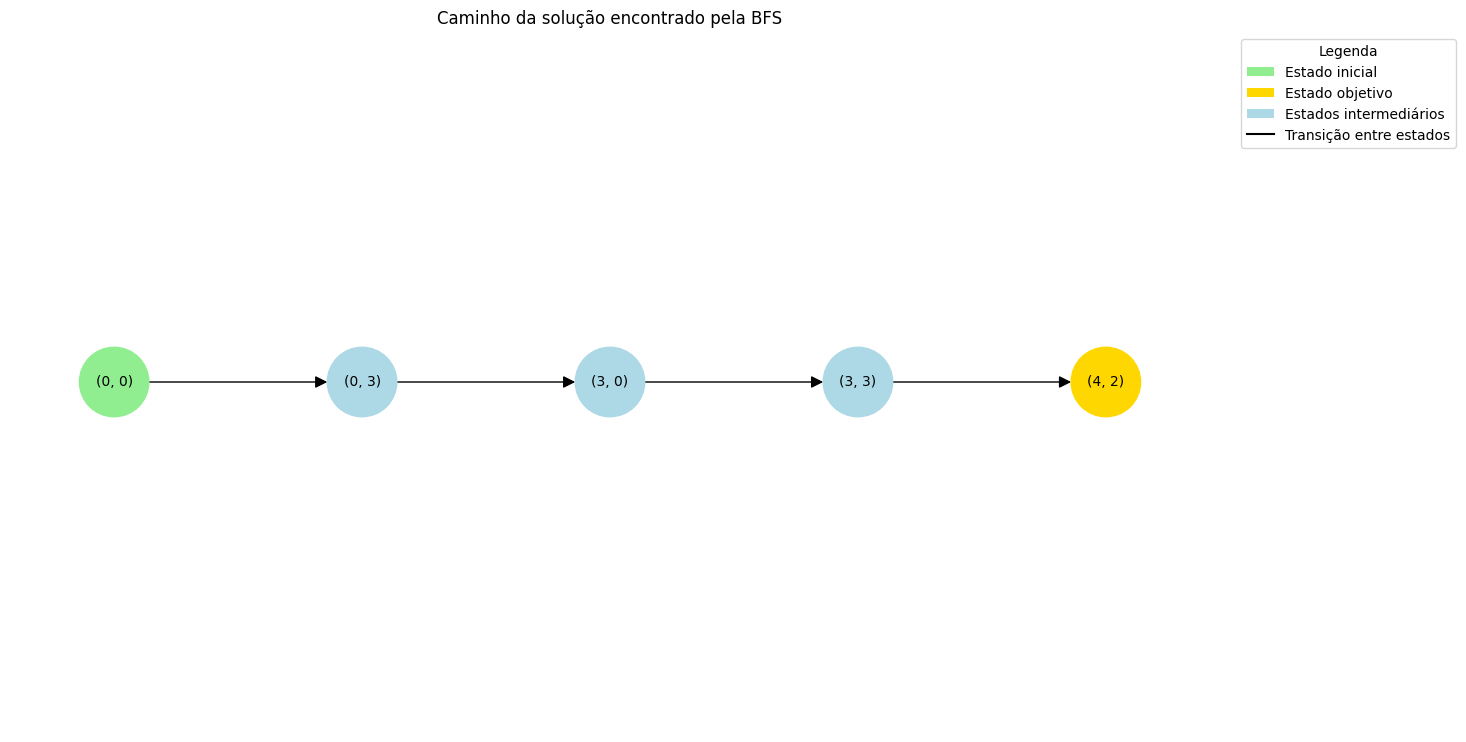

In [86]:
grafo_bfs = nx.DiGraph()

for i, estado in enumerate(solucao_bfs):
    grafo_bfs.add_node(estado)

    if i > 0:
        grafo_bfs.add_edge(solucao_bfs[i - 1], estado)

niveis = {estado_inicial: 0}

for estado in nx.topological_sort(grafo_bfs):
    for sucessor in grafo_bfs.successors(estado):
        niveis[sucessor] = niveis[estado] + 1

nx.set_node_attributes(grafo_bfs, niveis, "nivel")

posicoes = nx.multipartite_layout(
    grafo_bfs,
    subset_key="nivel",
    align="vertical",
    scale=2
)

posicoes = {
    estado: (x, -y)
    for estado, (x, y) in posicoes.items()
}

estado_objetivo = solucao_bfs[-1]

cores = []
for estado in grafo_bfs.nodes():
    if estado == estado_inicial:
        cores.append("lightgreen")
    elif estado == estado_objetivo:
        cores.append("gold")
    else:
        cores.append("lightblue")

plt.figure(figsize=(12, 7))

nx.draw(
    grafo_bfs,
    posicoes,
    with_labels=True,
    labels={estado: str(estado) for estado in grafo_bfs.nodes()},
    node_color=cores,
    node_size=2500,
    font_size=10,
    arrows=True,
    arrowsize=18
)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legenda = [
    Patch(facecolor="lightgreen", label="Estado inicial"),
    Patch(facecolor="gold", label="Estado objetivo"),
    Patch(facecolor="lightblue", label="Estados intermediários"),
    Line2D([0], [0], color="black", lw=1.5, label="Transição entre estados")
]

plt.legend(
    handles=legenda,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title="Legenda"
)

plt.title("Caminho da solução encontrado pela BFS")

plt.subplots_adjust(right=0.75, bottom=0.12, top=0.90)

plt.show()

### 6.5. Registro da árvore de busca da BFS

Além de encontrar o caminho até o estado objetivo, o algoritmo registrará os estados gerados e as transições realizadas durante a busca.

Cada aresta da árvore representa a ligação entre um estado explorado e um novo estado descoberto a partir dele. Esse registro permitirá visualizar os diferentes ramos percorridos pela busca em largura e destacar o caminho que conduz à solução.

In [87]:
def busca_largura_com_arvore(estado_inicial):
    fila = deque()
    fila.append((estado_inicial, [estado_inicial]))

    visitados = {estado_inicial}
    arvore = nx.DiGraph()

    arvore.add_node(estado_inicial)

    while fila:
        estado, caminho = fila.popleft()

        if eh_objetivo(estado):
            return caminho, arvore

        for sucessor in gerar_sucessores(estado):
            if sucessor not in visitados:
                visitados.add(sucessor)

                arvore.add_node(sucessor)
                arvore.add_edge(estado, sucessor)

                novo_caminho = caminho + [sucessor]
                fila.append((sucessor, novo_caminho))

    return None, arvore

In [88]:
solucao_bfs_arvore, arvore_bfs = busca_largura_com_arvore(estado_inicial)

print("Solução encontrada:", solucao_bfs_arvore)
print("Quantidade de ações:", len(solucao_bfs_arvore) - 1)
print("Estados registrados na árvore:", arvore_bfs.number_of_nodes())
print("Transições registradas:", arvore_bfs.number_of_edges())

Solução encontrada: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4
Estados registrados na árvore: 11
Transições registradas: 10


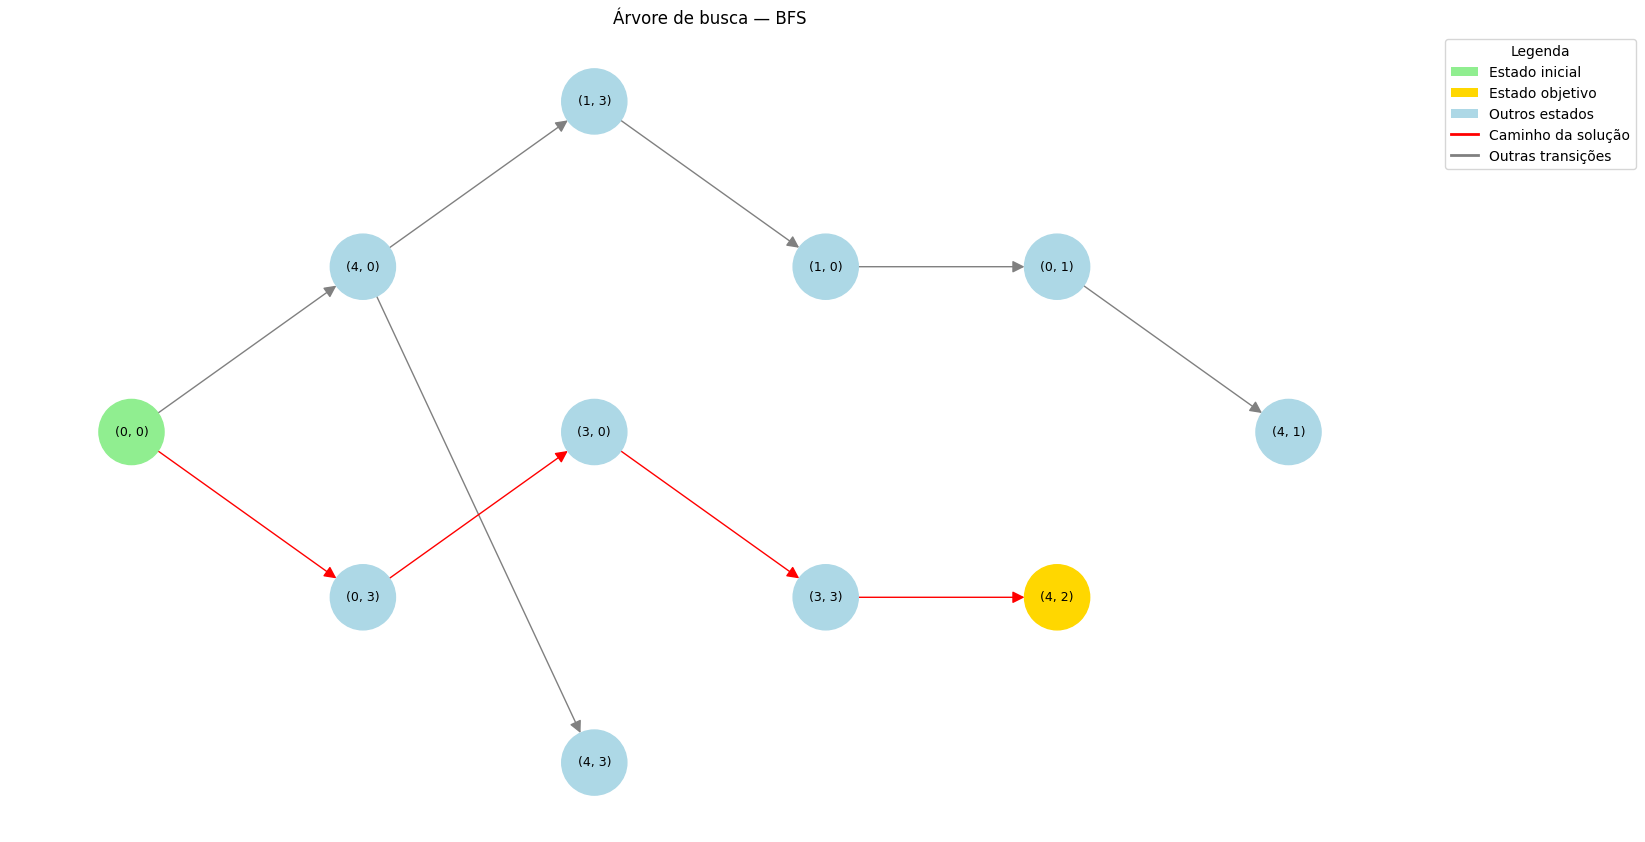

In [89]:
arestas_solucao = set(
    zip(solucao_bfs_arvore[:-1], solucao_bfs_arvore[1:])
)

niveis = {estado_inicial: 0}

for estado in nx.topological_sort(arvore_bfs):
    for sucessor in arvore_bfs.successors(estado):
        niveis[sucessor] = niveis[estado] + 1

nx.set_node_attributes(arvore_bfs, niveis, "nivel")

posicoes = nx.multipartite_layout(
    arvore_bfs,
    subset_key="nivel",
    align="vertical",
    scale=2
)

posicoes = {
    estado: (x, -y)
    for estado, (x, y) in posicoes.items()
}

cores_nos = []

for estado in arvore_bfs.nodes():
    if estado == estado_inicial:
        cores_nos.append("lightgreen")
    elif estado == solucao_bfs_arvore[-1]:
        cores_nos.append("gold")
    else:
        cores_nos.append("lightblue")

cores_arestas = [
    "red" if (origem, destino) in arestas_solucao else "gray"
    for origem, destino in arvore_bfs.edges()
]

plt.figure(figsize=(14, 8))

nx.draw(
    arvore_bfs,
    posicoes,
    with_labels=True,
    labels={estado: str(estado) for estado in arvore_bfs.nodes()},
    node_color=cores_nos,
    edge_color=cores_arestas,
    node_size=2200,
    font_size=9,
    arrows=True,
    arrowsize=18
)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legenda = [
    Patch(facecolor="lightgreen", label="Estado inicial"),
    Patch(facecolor="gold", label="Estado objetivo"),
    Patch(facecolor="lightblue", label="Outros estados"),
    Line2D([0], [0], color="red", lw=2, label="Caminho da solução"),
    Line2D([0], [0], color="gray", lw=2, label="Outras transições")
]

plt.legend(
    handles=legenda,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title="Legenda"
)

plt.title("Árvore de busca — BFS")
plt.subplots_adjust(right=0.78, bottom=0.12, top=0.90)
plt.show()


## 7. Busca em profundidade (DFS)

A busca em profundidade (*Depth-First Search — DFS*) explora um ramo do espaço de estados o mais profundamente possível antes de retornar (*backtracking*) e explorar outras alternativas.

Para controlar a exploração, será utilizada uma pilha LIFO (*Last In, First Out*), em que o último elemento inserido é o primeiro a ser removido. Um conjunto de estados visitados será utilizado para evitar explorações repetidas.

In [90]:
pilha = []

pilha.append((0, 0))
pilha.append((4, 0))
pilha.append((4, 3))

print("Pilha:", pilha)

estado = pilha.pop()

print("Estado removido:", estado)
print("Pilha após a remoção:", pilha)

Pilha: [(0, 0), (4, 0), (4, 3)]
Estado removido: (4, 3)
Pilha após a remoção: [(0, 0), (4, 0)]


### 7.1. Implementação da busca em profundidade (DFS)

O algoritmo DFS utiliza uma pilha para controlar os estados que serão explorados. A cada iteração, remove o último estado inserido, verifica se ele satisfaz o objetivo e, caso contrário, adiciona à pilha os sucessores ainda não visitados.

Quando o estado objetivo é encontrado, o algoritmo retorna o caminho correspondente. Caso a pilha fique vazia sem encontrar uma solução, retorna `None`.

In [91]:
def busca_profundidade(estado_inicial):
    pilha = [(estado_inicial, [estado_inicial])]
    visitados = {estado_inicial}

    while pilha:
        estado, caminho = pilha.pop()

        if eh_objetivo(estado):
            return caminho

        for sucessor in gerar_sucessores(estado):
            if sucessor not in visitados:
                visitados.add(sucessor)
                novo_caminho = caminho + [sucessor]
                pilha.append((sucessor, novo_caminho))

    return None

In [92]:
solucao_dfs = busca_profundidade(estado_inicial)

print("Caminho encontrado:", solucao_dfs)
print("Quantidade de ações:", len(solucao_dfs) - 1)

Caminho encontrado: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4


### 7.2. Visualização do caminho encontrado pela DFS

O caminho encontrado pela busca em profundidade será representado por um grafo direcionado. Cada nó representa um estado dos jarros, e cada seta indica a transição para o estado seguinte no caminho.

O estado inicial e o estado objetivo serão destacados por cores diferentes, acompanhados de uma legenda para facilitar a interpretação da sequência de estados que conduz à solução.

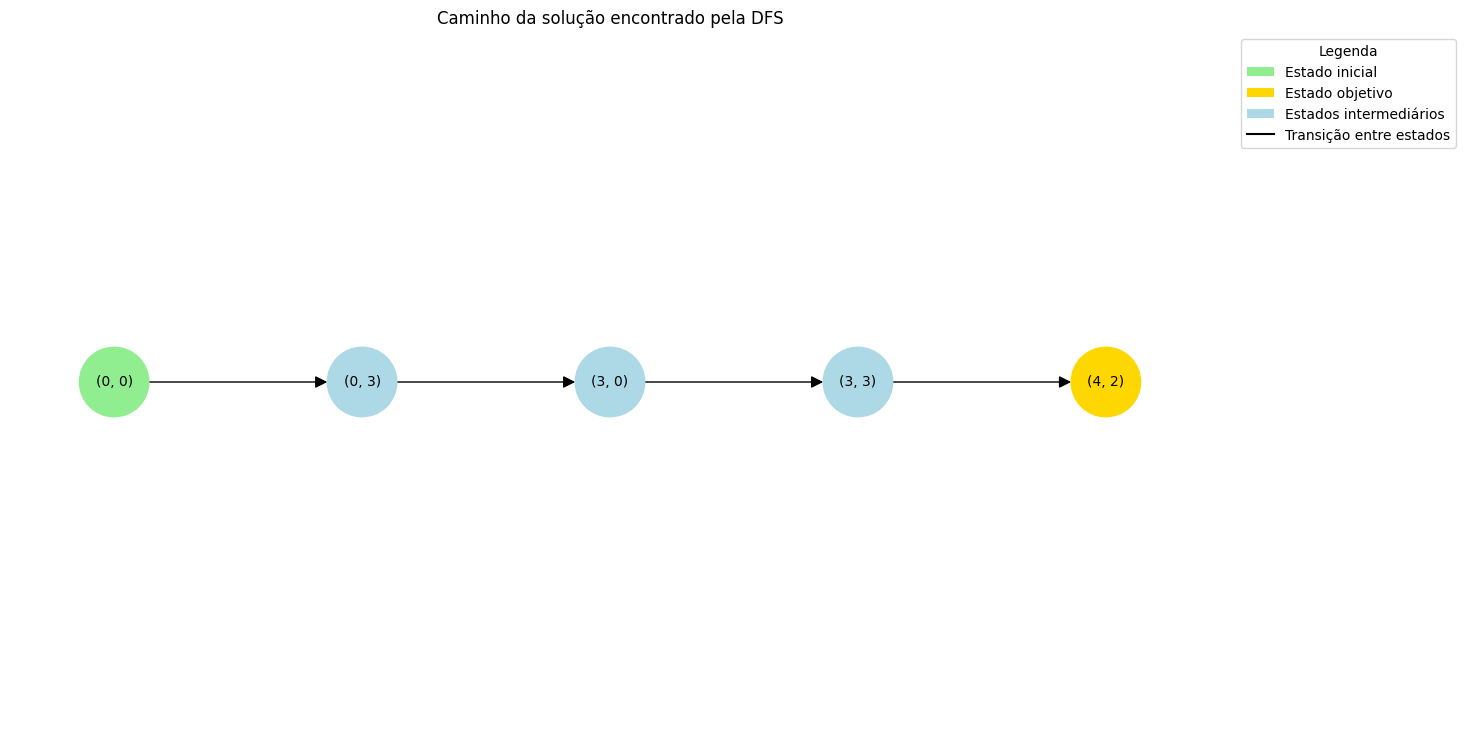

In [93]:
grafo_dfs = nx.DiGraph()

for i, estado in enumerate(solucao_dfs):
    grafo_dfs.add_node(estado)

    if i > 0:
        grafo_dfs.add_edge(solucao_dfs[i - 1], estado)

niveis_dfs = {estado_inicial: 0}

for estado in nx.topological_sort(grafo_dfs):
    for sucessor in grafo_dfs.successors(estado):
        niveis_dfs[sucessor] = niveis_dfs[estado] + 1

nx.set_node_attributes(grafo_dfs, niveis_dfs, "nivel")

posicoes_dfs = nx.multipartite_layout(
    grafo_dfs,
    subset_key="nivel",
    align="vertical",
    scale=2
)

posicoes_dfs = {
    estado: (x, -y)
    for estado, (x, y) in posicoes_dfs.items()
}

cores_dfs = []

for estado in grafo_dfs.nodes():
    if estado == estado_inicial:
        cores_dfs.append("lightgreen")
    elif estado == solucao_dfs[-1]:
        cores_dfs.append("gold")
    else:
        cores_dfs.append("lightblue")

plt.figure(figsize=(12, 7))

nx.draw(
    grafo_dfs,
    posicoes_dfs,
    with_labels=True,
    labels={estado: str(estado) for estado in grafo_dfs.nodes()},
    node_color=cores_dfs,
    node_size=2500,
    font_size=10,
    arrows=True,
    arrowsize=18
)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

legenda_dfs = [
    Patch(facecolor="lightgreen", label="Estado inicial"),
    Patch(facecolor="gold", label="Estado objetivo"),
    Patch(facecolor="lightblue", label="Estados intermediários"),
    Line2D([0], [0], color="black", lw=1.5, label="Transição entre estados")
]

plt.legend(
    handles=legenda_dfs,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title="Legenda"
)

plt.title("Caminho da solução encontrado pela DFS")
plt.subplots_adjust(right=0.75, bottom=0.12, top=0.90)
plt.show()

### 7.3. Registro da árvore de busca da DFS

Além de encontrar o caminho até o objetivo, o algoritmo registrará os estados descobertos e as transições entre eles durante a execução da busca.

A árvore permitirá visualizar os ramos explorados pela busca em profundidade. O caminho encontrado será destacado no gráfico, facilitando a identificação da sequência de transições que conduz à solução.

In [94]:
def busca_profundidade_com_arvore(estado_inicial):
    pilha = [(estado_inicial, [estado_inicial])]
    visitados = {estado_inicial}

    arvore = nx.DiGraph()
    arvore.add_node(estado_inicial)

    while pilha:
        estado, caminho = pilha.pop()

        if eh_objetivo(estado):
            return caminho, arvore

        for sucessor in gerar_sucessores(estado):
            if sucessor not in visitados:
                visitados.add(sucessor)

                arvore.add_node(sucessor)
                arvore.add_edge(estado, sucessor)

                novo_caminho = caminho + [sucessor]
                pilha.append((sucessor, novo_caminho))

    return None, arvore

### 7.4. Execução da busca em profundidade com registro da árvore

Nesta etapa, a função de busca em profundidade será executada a partir do estado inicial. Serão obtidos o caminho encontrado até o estado objetivo e o grafo que registra os estados descobertos e as transições realizadas durante a busca.

Também serão exibidas a quantidade de ações do caminho encontrado, o número de estados registrados e a quantidade de transições presentes no grafo.

In [95]:
solucao_dfs_arvore, arvore_dfs = busca_profundidade_com_arvore(estado_inicial)

print("Caminho encontrado:", solucao_dfs_arvore)
print("Quantidade de ações:", len(solucao_dfs_arvore) - 1)
print("Estados registrados na árvore:", arvore_dfs.number_of_nodes())
print("Transições registradas:", arvore_dfs.number_of_edges())

Caminho encontrado: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4
Estados registrados na árvore: 7
Transições registradas: 6


### 7.5. Visualização da árvore de busca da DFS

Nesta etapa, será apresentada a árvore de busca construída durante a execução do algoritmo de busca em profundidade (DFS), contendo os estados e as transições registrados até que o objetivo seja encontrado.

O estado inicial será destacado em verde, o estado objetivo em amarelo e os demais estados em azul. As arestas em vermelho representarão o caminho encontrado até a solução, enquanto as arestas em cinza indicarão as demais transições registradas durante a busca.

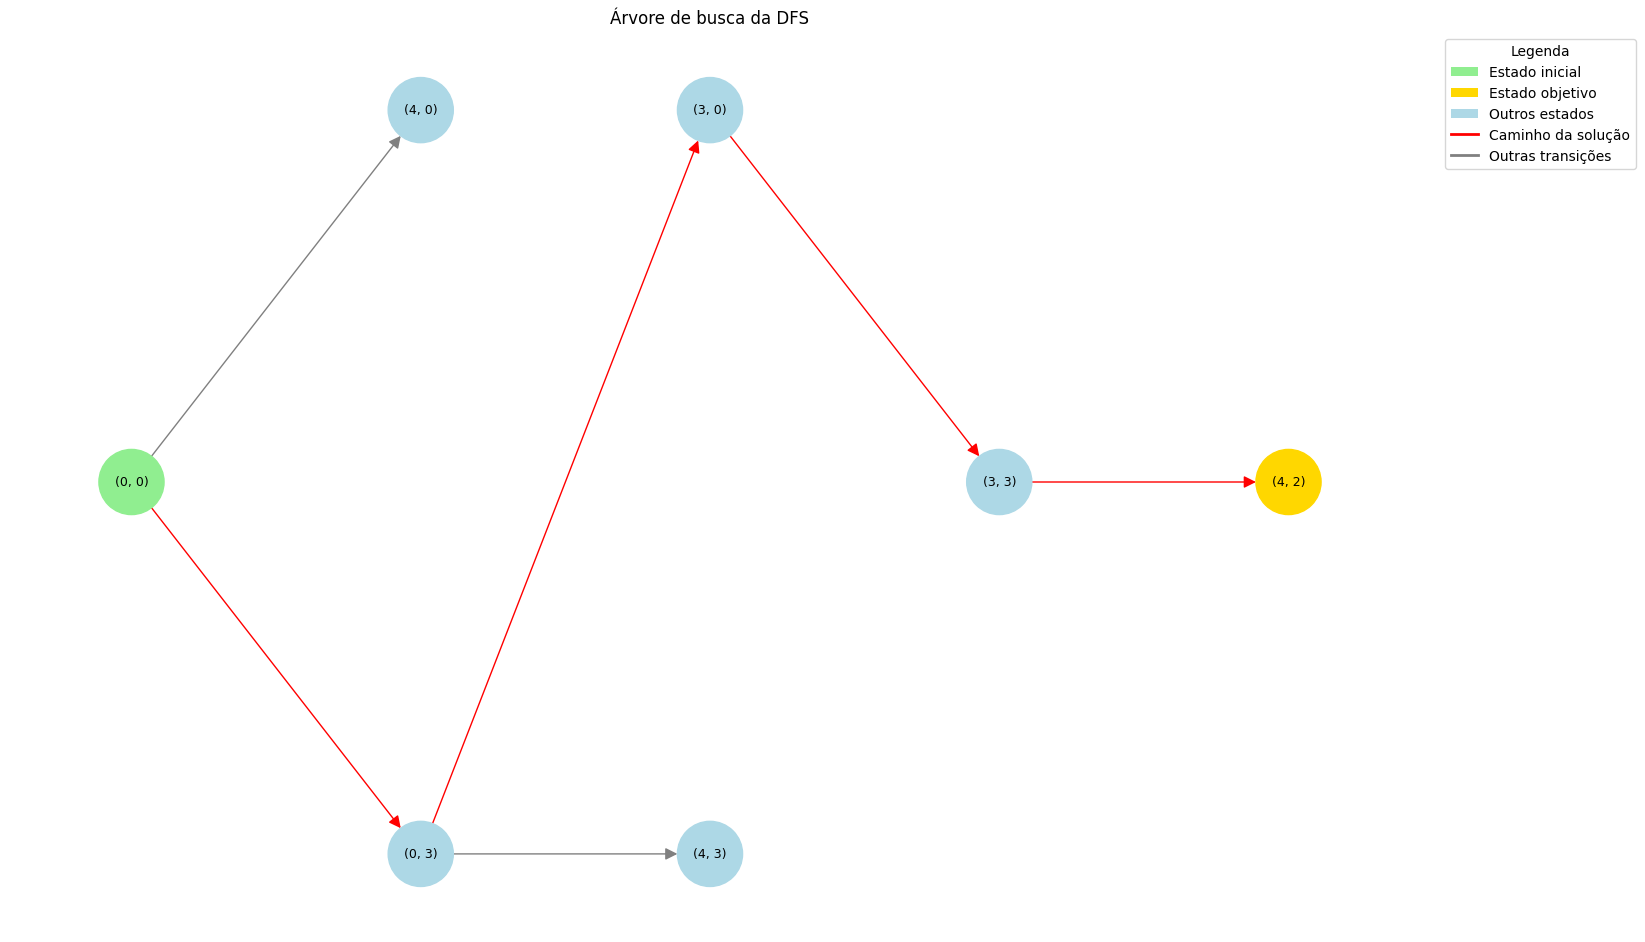

In [96]:
arestas_solucao_dfs = set(
    zip(solucao_dfs_arvore[:-1], solucao_dfs_arvore[1:])
)

niveis_dfs = {estado_inicial: 0}

for estado in nx.topological_sort(arvore_dfs):
    for sucessor in arvore_dfs.successors(estado):
        niveis_dfs[sucessor] = niveis_dfs[estado] + 1

nx.set_node_attributes(arvore_dfs, niveis_dfs, "nivel")

posicoes_dfs_arvore = nx.multipartite_layout(
    arvore_dfs,
    subset_key="nivel",
    align="vertical",
    scale=2
)

posicoes_dfs_arvore = {
    estado: (x, -y)
    for estado, (x, y) in posicoes_dfs_arvore.items()
}

cores_nos_dfs = []

for estado in arvore_dfs.nodes():
    if estado == estado_inicial:
        cores_nos_dfs.append("lightgreen")
    elif estado == solucao_dfs_arvore[-1]:
        cores_nos_dfs.append("gold")
    else:
        cores_nos_dfs.append("lightblue")

cores_arestas_dfs = [
    "red" if (origem, destino) in arestas_solucao_dfs else "gray"
    for origem, destino in arvore_dfs.edges()
]

plt.figure(figsize=(14, 9))

nx.draw(
    arvore_dfs,
    pos=posicoes_dfs_arvore,
    with_labels=True,
    labels={estado: str(estado) for estado in arvore_dfs.nodes()},
    node_color=cores_nos_dfs,
    edge_color=cores_arestas_dfs,
    node_size=2200,
    font_size=9,
    arrows=True,
    arrowsize=18
)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

legenda_dfs = [
    Patch(facecolor="lightgreen", label="Estado inicial"),
    Patch(facecolor="gold", label="Estado objetivo"),
    Patch(facecolor="lightblue", label="Outros estados"),
    Line2D([0], [0], color="red", lw=2, label="Caminho da solução"),
    Line2D([0], [0], color="gray", lw=2, label="Outras transições")
]

plt.legend(
    handles=legenda_dfs,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title="Legenda"
)

plt.title("Árvore de busca da DFS")
plt.subplots_adjust(right=0.75, bottom=0.10, top=0.92)
plt.show()

## 8. Busca por Aprofundamento Iterativo (IDS)

A busca por aprofundamento iterativo (*Iterative Deepening Search — IDS*) combina características da busca em profundidade (DFS) e da busca em largura (BFS). O algoritmo executa buscas em profundidade com limites crescentes, começando no nível zero e aumentando o limite em uma unidade a cada nova tentativa, até encontrar o estado objetivo.

Essa estratégia permite explorar estados progressivamente mais profundos sem precisar manter todos os estados de uma mesma camada na memória, como ocorre na busca em largura. Entretanto, estados próximos à raiz podem ser explorados novamente em diferentes iterações, gerando trabalho repetido.

In [97]:
def busca_profundidade_limitada(estado_inicial, limite):
    pilha = [(estado_inicial, [estado_inicial])]

    while pilha:
        estado, caminho = pilha.pop()
        profundidade = len(caminho) - 1

        if eh_objetivo(estado):
            return caminho

        if profundidade < limite:
            for sucessor in gerar_sucessores(estado):
                if sucessor not in caminho:
                    novo_caminho = caminho + [sucessor]
                    pilha.append((sucessor, novo_caminho))

    return None

In [98]:
for limite in range(5):
    resultado = busca_profundidade_limitada(estado_inicial, limite)

    print(f"Limite {limite}:")

    if resultado is None:
        print("  Nenhuma solução encontrada nesse limite.")
    else:
        print("  Caminho:", resultado)
        print("  Quantidade de ações:", len(resultado) - 1)

    print()

Limite 0:
  Nenhuma solução encontrada nesse limite.

Limite 1:
  Nenhuma solução encontrada nesse limite.

Limite 2:
  Nenhuma solução encontrada nesse limite.

Limite 3:
  Nenhuma solução encontrada nesse limite.

Limite 4:
  Caminho: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
  Quantidade de ações: 4



### 8.1. Implementação da busca por aprofundamento iterativo

A busca por aprofundamento iterativo executa repetidamente a busca em profundidade limitada, aumentando o limite de profundidade em uma unidade a cada iteração, começando em zero.

O processo termina quando o estado objetivo é encontrado ou quando o limite máximo definido é atingido sem encontrar uma solução. Em cada tentativa, a busca começa novamente a partir do estado inicial.

In [99]:
def busca_aprofundamento_iterativo(estado_inicial, limite_maximo=20):
    for limite in range(limite_maximo + 1):
        resultado = busca_profundidade_limitada(
            estado_inicial,
            limite
        )

        if resultado is not None:
            return resultado

    return None

### 8.2. Execução da busca por aprofundamento iterativo

Nesta etapa, o algoritmo IDS será executado a partir do estado inicial. A função realizará buscas em profundidade limitada com limites crescentes até encontrar o estado objetivo ou atingir o limite máximo definido.

O resultado apresentará o caminho encontrado até o objetivo e a quantidade de ações necessárias para alcançar a solução.

In [100]:

solucao_ids = busca_aprofundamento_iterativo(estado_inicial)

print("Caminho encontrado:", solucao_ids)

if solucao_ids is not None:
    print("Quantidade de ações:", len(solucao_ids) - 1)
else:
    print("Nenhuma solução encontrada.")

Caminho encontrado: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4


### 8.3. Registro da árvore de busca do IDS

Nesta etapa, será registrado um grafo com os estados e as transições identificados durante as buscas realizadas pelo algoritmo IDS até encontrar o objetivo.

Como o aprofundamento iterativo executa várias buscas em profundidade com limites crescentes, um mesmo estado ou uma mesma transição pode aparecer em diferentes iterações. Na visualização, essas ocorrências serão reunidas em uma representação agregada, que permite observar os estados e as transições registrados, mas não mostra separadamente cada ocorrência repetida.

In [101]:
def registrar_caminho_ids(caminho):
    arvore = nx.DiGraph()

    for i, estado in enumerate(caminho):
        arvore.add_node(estado)

        if i > 0:
            arvore.add_edge(caminho[i - 1], estado)

    return arvore


arvore_ids = registrar_caminho_ids(solucao_ids)

print("Estados no caminho:", arvore_ids.number_of_nodes())
print("Transições no caminho:", arvore_ids.number_of_edges())

Estados no caminho: 5
Transições no caminho: 4


### 8.4. Visualização do caminho da solução do IDS

O grafo a seguir representa o caminho encontrado pela busca por aprofundamento iterativo (IDS). Cada nó corresponde a um estado dos jarros, e cada seta representa a transição para o estado seguinte.

O estado inicial será destacado em verde, o estado objetivo em amarelo e os estados intermediários em azul. As transições que compõem o caminho da solução serão representadas em vermelho.

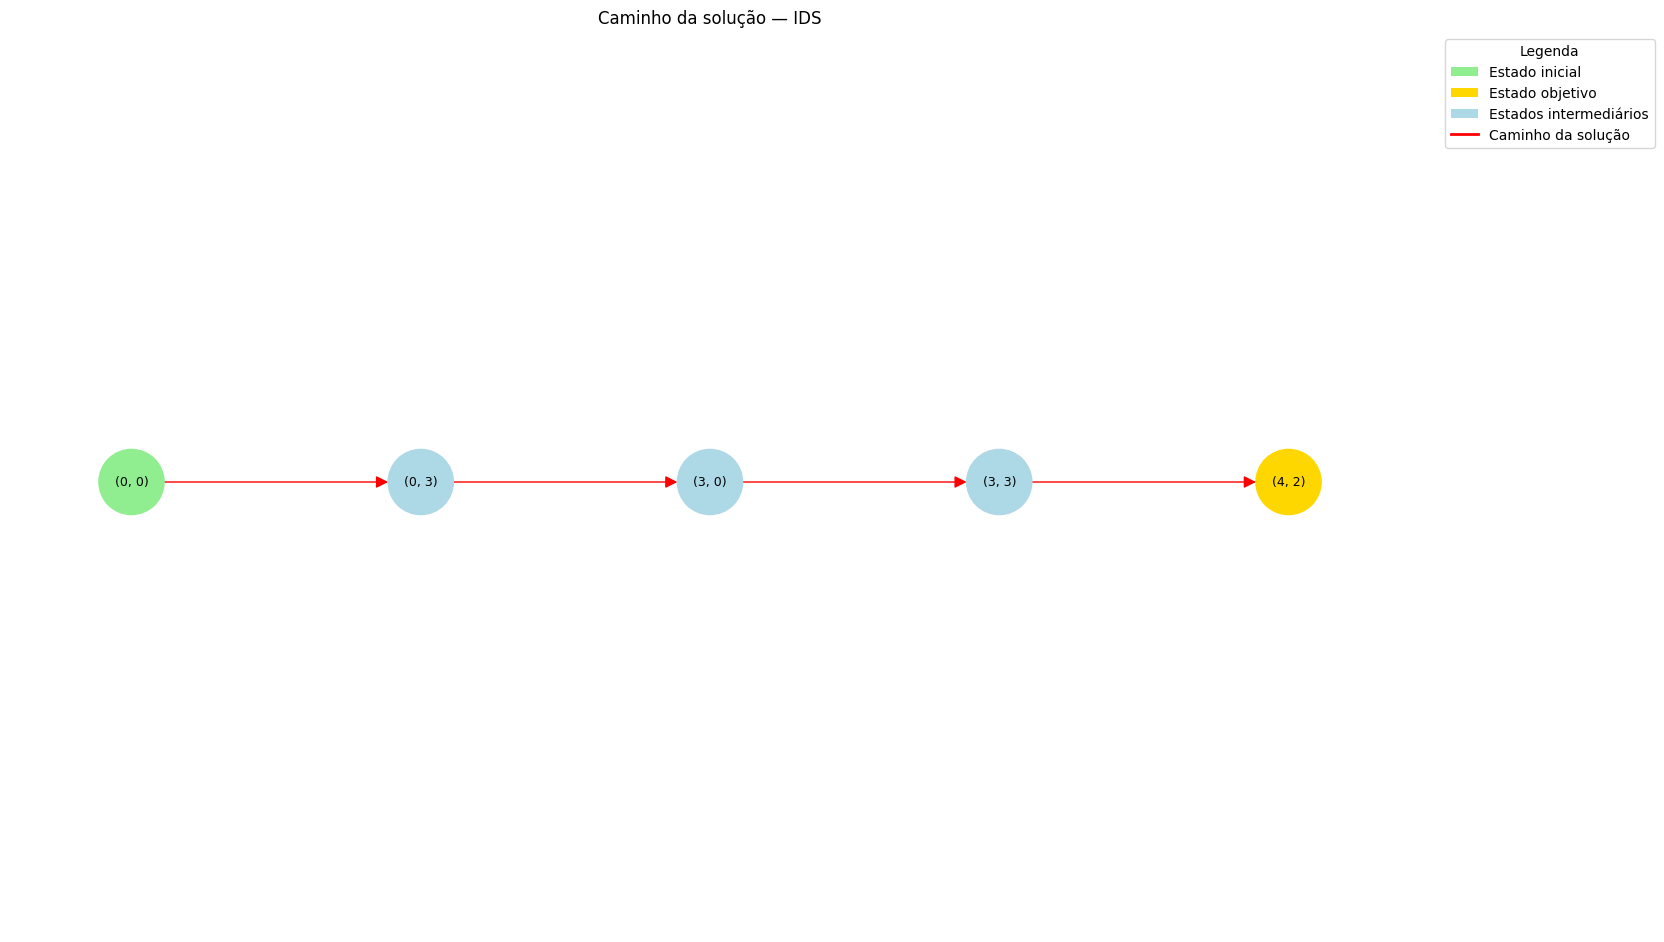

In [102]:
niveis_ids = {estado_inicial: 0}

for estado in nx.topological_sort(arvore_ids):
    for sucessor in arvore_ids.successors(estado):
        niveis_ids[sucessor] = niveis_ids[estado] + 1

nx.set_node_attributes(arvore_ids, niveis_ids, "nivel")

posicoes_ids = nx.multipartite_layout(
    arvore_ids,
    subset_key="nivel",
    align="vertical",
    scale=2
)

posicoes_ids = {
    estado: (x, -y)
    for estado, (x, y) in posicoes_ids.items()
}

cores_nos_ids = []

for estado in arvore_ids.nodes():
    if estado == estado_inicial:
        cores_nos_ids.append("lightgreen")
    elif estado == solucao_ids[-1]:
        cores_nos_ids.append("gold")
    else:
        cores_nos_ids.append("lightblue")

cores_arestas_ids = ["red"] * arvore_ids.number_of_edges()

plt.figure(figsize=(14, 9))

nx.draw(
    arvore_ids,
    pos=posicoes_ids,
    with_labels=True,
    labels={estado: str(estado) for estado in arvore_ids.nodes()},
    node_color=cores_nos_ids,
    edge_color=cores_arestas_ids,
    node_size=2200,
    font_size=9,
    arrows=True,
    arrowsize=18
)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

legenda_ids = [
    Patch(facecolor="lightgreen", label="Estado inicial"),
    Patch(facecolor="gold", label="Estado objetivo"),
    Patch(facecolor="lightblue", label="Estados intermediários"),
    Line2D([0], [0], color="red", lw=2, label="Caminho da solução")
]

plt.legend(
    handles=legenda_ids,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title="Legenda"
)

plt.title("Caminho da solução — IDS")
plt.subplots_adjust(right=0.75, bottom=0.10, top=0.92)
plt.show()

### 8.5. Registro da árvore de busca do IDS

Nesta etapa, será registrado o processo de exploração do algoritmo de aprofundamento iterativo. Para isso, serão consideradas as transições geradas em cada busca em profundidade limitada, desde o limite inicial zero até a iteração em que o estado objetivo for encontrado.

Como o IDS pode explorar novamente os mesmos estados e transições em diferentes iterações, o registro deverá preservar essa característica para representar o trabalho realizado pelo algoritmo, distinguindo as explorações repetidas do caminho final da solução.

In [103]:
def busca_ids_com_arvore(estado_inicial, limite_maximo=20):
    arvore = nx.DiGraph()
    arvore.add_node(estado_inicial)

    for limite in range(limite_maximo + 1):
        pilha = [(estado_inicial, [estado_inicial], 0)]

        while pilha:
            estado, caminho, profundidade = pilha.pop()

            if eh_objetivo(estado):
                return caminho, arvore, limite

            if profundidade < limite:
                for sucessor in gerar_sucessores(estado):
                    if sucessor not in caminho:
                        arvore.add_node(sucessor)
                        arvore.add_edge(estado, sucessor)

                        pilha.append(
                            (sucessor, caminho + [sucessor], profundidade + 1)
                        )

    return None, arvore, limite_maximo

### 8.7. Execução da busca IDS com registro da árvore

Nesta etapa, a busca por aprofundamento iterativo será executada com o registro das transições exploradas. Serão apresentados o caminho encontrado, a quantidade de ações, o limite de profundidade em que a solução foi encontrada e as quantidades de estados e transições registradas.

In [104]:
solucao_ids_arvore, arvore_ids_completa, limite_ids = busca_ids_com_arvore(
    estado_inicial
)

print("Caminho encontrado:", solucao_ids_arvore)

if solucao_ids_arvore is not None:
    print("Quantidade de ações:", len(solucao_ids_arvore) - 1)
    print("Limite de profundidade:", limite_ids)
else:
    print("Nenhuma solução encontrada dentro do limite definido.")

print("Estados registrados:", arvore_ids_completa.number_of_nodes())
print("Transições registradas:", arvore_ids_completa.number_of_edges())


Caminho encontrado: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4
Limite de profundidade: 4
Estados registrados: 9
Transições registradas: 15


### 8.8. Visualização da árvore de busca do IDS

O grafo abaixo representa os estados e as transições registrados durante as iterações do IDS até encontrar o objetivo. O estado inicial será destacado em verde, o objetivo em amarelo e os demais estados em azul. As transições pertencentes ao caminho da solução serão destacadas em vermelho, enquanto as demais serão exibidas em cinza.

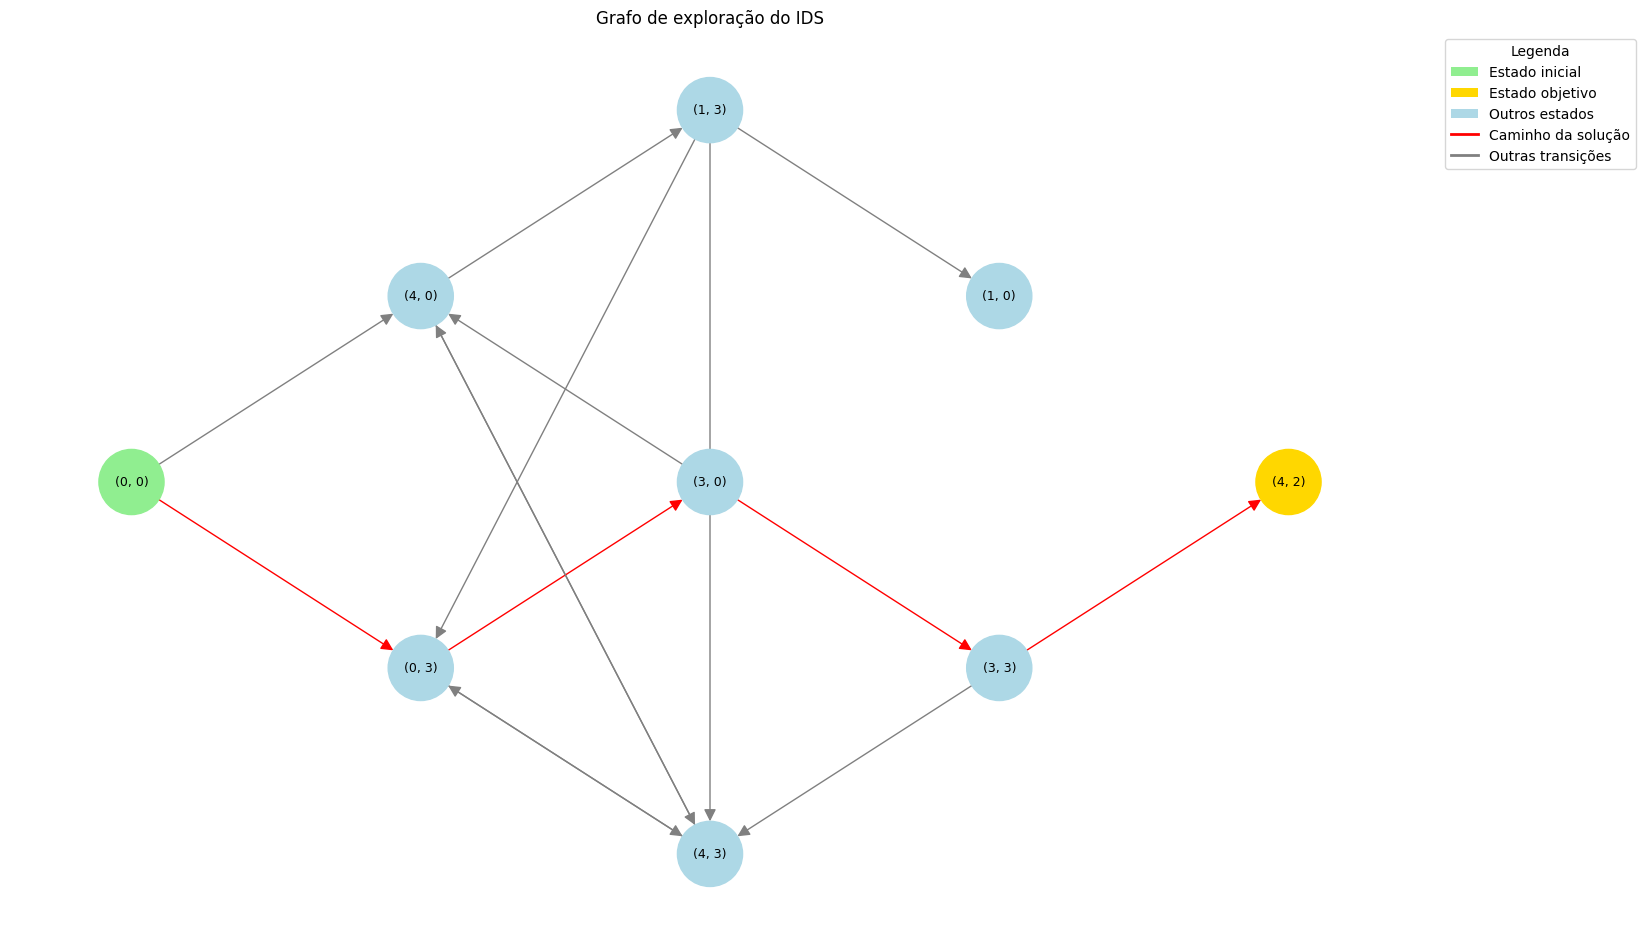

In [105]:
from collections import deque

arestas_solucao_ids = set(
    zip(solucao_ids_arvore[:-1], solucao_ids_arvore[1:])
)

niveis_ids_arvore = {estado_inicial: 0}
fila_niveis = deque([estado_inicial])

while fila_niveis:
    estado = fila_niveis.popleft()

    for sucessor in arvore_ids_completa.successors(estado):
        if sucessor not in niveis_ids_arvore:
            niveis_ids_arvore[sucessor] = niveis_ids_arvore[estado] + 1
            fila_niveis.append(sucessor)

nx.set_node_attributes(arvore_ids_completa, niveis_ids_arvore, "nivel")


posicoes_ids_arvore = nx.multipartite_layout(
    arvore_ids_completa,
    subset_key="nivel",
    align="vertical",
    scale=2
)

posicoes_ids_arvore = {
    estado: (x, -y)
    for estado, (x, y) in posicoes_ids_arvore.items()
}

cores_nos_ids_arvore = []

for estado in arvore_ids_completa.nodes():
    if estado == estado_inicial:
        cores_nos_ids_arvore.append("lightgreen")
    elif estado == solucao_ids_arvore[-1]:
        cores_nos_ids_arvore.append("gold")
    else:
        cores_nos_ids_arvore.append("lightblue")

cores_arestas_ids_arvore = [
    "red" if (origem, destino) in arestas_solucao_ids else "gray"
    for origem, destino in arvore_ids_completa.edges()
]

plt.figure(figsize=(14, 9))

nx.draw(
    arvore_ids_completa,
    pos=posicoes_ids_arvore,
    with_labels=True,
    labels={
        estado: str(estado)
        for estado in arvore_ids_completa.nodes()
    },
    node_color=cores_nos_ids_arvore,
    edge_color=cores_arestas_ids_arvore,
    node_size=2200,
    font_size=9,
    arrows=True,
    arrowsize=18
)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

legenda_ids_arvore = [
    Patch(facecolor="lightgreen", label="Estado inicial"),
    Patch(facecolor="gold", label="Estado objetivo"),
    Patch(facecolor="lightblue", label="Outros estados"),
    Line2D([0], [0], color="red", lw=2, label="Caminho da solução"),
    Line2D([0], [0], color="gray", lw=2, label="Outras transições")
]

plt.legend(
    handles=legenda_ids_arvore,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    title="Legenda"
)

plt.title("Grafo de exploração do IDS")
plt.subplots_adjust(right=0.75, bottom=0.10, top=0.92)
plt.show()

## 9. Comparação entre os algoritmos de busca

Nesta seção, serão comparados os algoritmos de busca em largura (BFS), busca em profundidade (DFS) e busca por aprofundamento iterativo (IDS). A comparação considerará o caminho encontrado, a quantidade de ações necessárias para alcançar o objetivo e o tempo de execução de cada algoritmo.

In [106]:
print("=== COMPARAÇÃO DOS CAMINHOS ===\n")

print("BFS — Busca em largura")
print("Caminho:", solucao_bfs)
print("Quantidade de ações:", len(solucao_bfs) - 1)
print()

print("DFS — Busca em profundidade")
print("Caminho:", solucao_dfs)
print("Quantidade de ações:", len(solucao_dfs) - 1)
print()

print("IDS — Aprofundamento iterativo")
print("Caminho:", solucao_ids)
print("Quantidade de ações:", len(solucao_ids) - 1)

=== COMPARAÇÃO DOS CAMINHOS ===

BFS — Busca em largura
Caminho: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4

DFS — Busca em profundidade
Caminho: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4

IDS — Aprofundamento iterativo
Caminho: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2)]
Quantidade de ações: 4


### 9.1. Medição do tempo de execução

Nesta etapa, será medido o tempo de execução dos algoritmos BFS, DFS e IDS. Para tornar a comparação mais confiável, cada algoritmo será executado várias vezes, e será calculada a média dos tempos obtidos.

In [107]:
import time

def medir_tempo(funcao, estado_inicial, repeticoes=1000):
    inicio = time.perf_counter()

    for _ in range(repeticoes):
        funcao(estado_inicial)

    fim = time.perf_counter()

    tempo_medio = (fim - inicio) / repeticoes
    return tempo_medio

tempo_bfs = medir_tempo(busca_largura, estado_inicial)
tempo_dfs = medir_tempo(busca_profundidade, estado_inicial)
tempo_ids = medir_tempo(busca_aprofundamento_iterativo, estado_inicial)

print(f"Tempo médio BFS: {tempo_bfs:.8f} segundos")
print(f"Tempo médio DFS: {tempo_dfs:.8f} segundos")
print(f"Tempo médio IDS: {tempo_ids:.8f} segundos")


Tempo médio BFS: 0.00004186 segundos
Tempo médio DFS: 0.00001820 segundos
Tempo médio IDS: 0.00006493 segundos


### 9.2. Gráfico comparativo do tempo de execução

O gráfico apresenta o tempo médio de execução dos três algoritmos. Os valores são convertidos de segundos para microssegundos para facilitar a visualização e a comparação dos resultados.

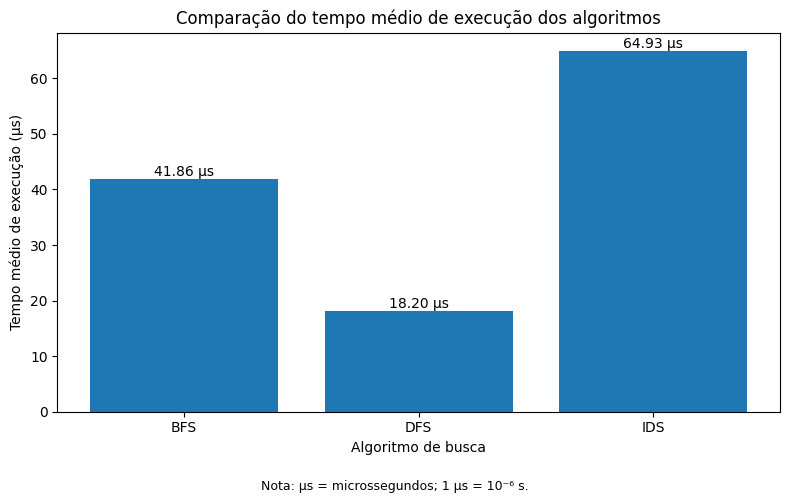

In [108]:
algoritmos = ["BFS", "DFS", "IDS"]

tempos_microsegundos = [
    tempo_bfs * 1_000_000,
    tempo_dfs * 1_000_000,
    tempo_ids * 1_000_000
]

plt.figure(figsize=(8, 5))

barras = plt.bar(algoritmos, tempos_microsegundos)

plt.title("Comparação do tempo médio de execução dos algoritmos")
plt.xlabel("Algoritmo de busca")
plt.ylabel("Tempo médio de execução (µs)")

for barra, tempo in zip(barras, tempos_microsegundos):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{tempo:.2f} µs",
        ha="center",
        va="bottom"
    )

plt.figtext(
    0.5, 0.01,
    "Nota: µs = microssegundos; 1 µs = 10⁻⁶ s.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### 9.3. Tabela comparativa dos resultados

A tabela a seguir reúne os resultados obtidos durante a execução dos algoritmos de busca em largura (BFS), busca em profundidade (DFS) e aprofundamento iterativo (IDS). São apresentados o número de ações necessárias para alcançar o estado objetivo e o tempo médio de execução de cada algoritmo.

Esses dados permitem comparar o desempenho observado nas execuções e verificar se os algoritmos encontraram soluções com a mesma quantidade de ações.

In [109]:
import pandas as pd

comparacao = pd.DataFrame({
    "Algoritmo": ["BFS", "DFS", "IDS"],
    "Quantidade de ações": [
        len(solucao_bfs) - 1,
        len(solucao_dfs) - 1,
        len(solucao_ids) - 1
    ],
    "Tempo médio (µs)": [
        tempo_bfs * 1_000_000,
        tempo_dfs * 1_000_000,
        tempo_ids * 1_000_000
    ]
})

comparacao["Tempo médio (µs)"] = comparacao["Tempo médio (µs)"].round(2)

display(comparacao)

,Algoritmo,Quantidade de ações,Tempo médio (µs)
0,BFS,4,41.86
1,DFS,4,18.20
2,IDS,4,64.93


#### Gráfico comparativo da quantidade de ações

O gráfico apresenta a quantidade de ações necessárias para alcançar o estado objetivo utilizando os algoritmos BFS, DFS e IDS. Nesta execução, os três algoritmos encontraram soluções compostas por quatro ações.

Esse resultado permite comparar as soluções encontradas neste teste. Entretanto, a quantidade de ações observada em uma execução não é suficiente, isoladamente, para demonstrar a otimalidade de todos os algoritmos, pois essa propriedade depende das características teóricas de cada estratégia de busca.

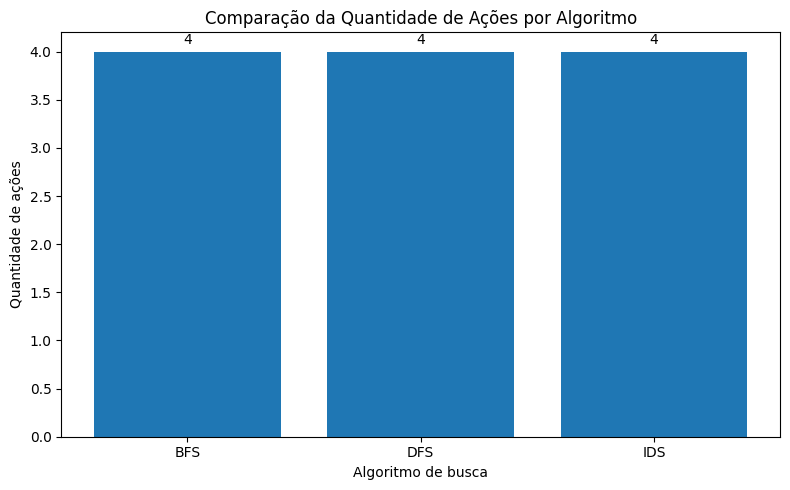

In [110]:

import matplotlib.pyplot as plt

algoritmos = ["BFS", "DFS", "IDS"]

quantidade_acoes = [
    len(solucao_bfs) - 1,
    len(solucao_dfs) - 1,
    len(solucao_ids) - 1
]

plt.figure(figsize=(8, 5))

barras = plt.bar(algoritmos, quantidade_acoes)

plt.title("Comparação da Quantidade de Ações por Algoritmo")
plt.xlabel("Algoritmo de busca")
plt.ylabel("Quantidade de ações")
plt.bar_label(barras, padding=3)

plt.tight_layout()
plt.show()

### 9.4. Análise dos resultados experimentais

Os três algoritmos encontraram uma solução composta por quatro ações nesta execução. Embora tenham encontrado uma solução com a mesma quantidade de ações, cada estratégia utiliza um procedimento diferente para explorar os estados.

A busca em largura (BFS) explora os estados por níveis e encontra uma solução com o menor número de ações quando todas as ações possuem o mesmo custo. A busca em profundidade (DFS) explora um caminho antes de retornar para investigar alternativas, não garantindo, em geral, a solução com o menor número de ações. Já o aprofundamento iterativo (IDS) realiza buscas em profundidade com limites crescentes, repetindo parte da exploração a cada iteração.

Os tempos medidos apresentaram diferenças entre os algoritmos. Entretanto, como o espaço de estados deste problema é pequeno, esses valores representam apenas o comportamento observado durante os testes e podem variar conforme o ambiente de execução.

### 9.5. Análise teórica de complexidade

A análise teórica complementa os resultados experimentais por meio de critérios que descrevem o comportamento dos algoritmos conforme o tamanho do problema aumenta.

A complexidade de tempo está relacionada à quantidade de nós que podem ser gerados ou explorados, enquanto a complexidade de espaço considera a quantidade de nós que precisam ser armazenados durante a busca. A completude indica se o algoritmo consegue encontrar uma solução quando ela existe, sob determinadas condições. A otimalidade indica se o algoritmo garante a melhor solução segundo um critério definido, como a menor quantidade de ações.

Esses critérios permitem compreender as vantagens e limitações de cada estratégia, sem depender exclusivamente dos tempos medidos no problema dos jarros d’água.

### 9.6. Comparação teórica entre BFS, DFS e IDS

Para comparar os algoritmos, são considerados o fator de ramificação (\(b\)), a profundidade da solução mais rasa (\(d\)) e a profundidade máxima da busca (\(m\)).

A busca em largura (BFS) explora os estados por níveis. Por isso, pode precisar armazenar muitos nós na memória, mas encontra a solução com menor número de ações quando todas as ações possuem o mesmo custo.

A busca em profundidade (DFS) explora um caminho até determinado limite antes de retornar para investigar alternativas. Em geral, utiliza menos memória, mas não garante encontrar a solução ótima e pode não ser completa em espaços de busca com profundidade ilimitada.

O aprofundamento iterativo (IDS) executa buscas em profundidade com limites crescentes. Essa estratégia repete parte da exploração, mas combina a capacidade de encontrar soluções em profundidade limitada com um consumo de memória geralmente menor que o da busca em largura. <br> <br>

### Tabela de características

| Critério | BFS | DFS | IDS |
|---|---|---|---|
| **Estratégia** | Por níveis | Em profundidade | Limites crescentes |
| **Completude** | Sim* | Não em geral | Sim* |
| **Otimalidade** | Sim* | Não em geral | Sim* |
| **Vantagem** | Menor caminho em ações* | Menor uso de memória | Menor uso de memória que BFS* |
| **Limitação** | Alto uso de memória | Pode seguir caminhos longos | Repete explorações |

*Sob as condições explicadas no texto da seção 9.7. <br> <br>

### Tabela de complexidade

| Complexidade | BFS | DFS | IDS |
|---|---|---|---|
| **Tempo** | \(O(b^d)\) | \(O(b^m)\) | \(O(b^d)\) |
| **Espaço** | \(O(b^d)\) | \(O(bd)\) | \(O(bd)\) |

**Legenda:** \(b\) = fator de ramificação; \(d\) = profundidade da solução mais rasa; \(m\) = profundidade máxima da busca.

#### Análise gráfica da complexidade teórica

A notação Big-O descreve como o custo computacional de um algoritmo cresce conforme o tamanho do problema aumenta. Diferentemente dos gráficos experimentais, que apresentam tempos medidos durante a execução, a análise Big-O representa o comportamento teórico dos algoritmos.

Na busca em largura (BFS) e no aprofundamento iterativo (IDS), o custo de tempo está relacionado ao fator de ramificação e à profundidade da solução. Na busca em profundidade (DFS), o custo pode depender da profundidade máxima explorada.

As expressões utilizadas nesta análise são as apresentadas na comparação teórica: BFS, \(O(b^d)\); DFS, \(O(b^m)\); e IDS, \(O(b^d)\). Essas expressões descrevem o crescimento assintótico, não os tempos exatos de execução do problema dos jarros.

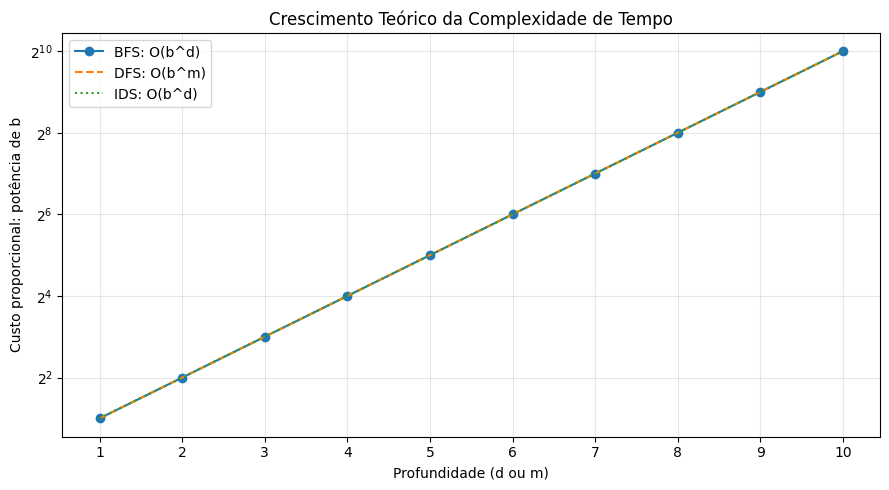

In [111]:

import matplotlib.pyplot as plt

b = 2
profundidade = list(range(1, 11))

bfs = [b**d for d in profundidade]
ids = [b**d for d in profundidade]

dfs = [b**m for m in profundidade]

plt.figure(figsize=(9, 5))

plt.plot(profundidade, bfs, marker="o", label="BFS: O(b^d)")
plt.plot(profundidade, dfs, linestyle="--", label="DFS: O(b^m)")
plt.plot(profundidade, ids, linestyle=":", label="IDS: O(b^d)")

plt.title("Crescimento Teórico da Complexidade de Tempo")
plt.xlabel("Profundidade (d ou m)")
plt.ylabel("Custo proporcional: potência de b")
plt.yscale("log", base=2)
plt.xticks(profundidade)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação do gráfico de complexidade teórica**

O gráfico apresenta um exemplo ilustrativo de crescimento exponencial, considerando o fator de ramificação \(b=2\). Como as expressões de tempo da BFS e da IDS são \(O(b^d)\), e a DFS foi representada utilizando \(m=d\), as três curvas coincidem nesta simulação.

Essa sobreposição não significa que os algoritmos tenham o mesmo desempenho em todos os problemas. A quantidade de nós explorados depende da estrutura do espaço de estados, da localização da solução e, no caso da DFS, da profundidade máxima alcançada. Portanto, o gráfico serve para ilustrar o crescimento exponencial, enquanto as diferenças entre as estratégias são discutidas na tabela teórica e nos resultados experimentais.

### 9.7. Conclusão

A implementação dos algoritmos de busca em largura (BFS), busca em profundidade (DFS) e aprofundamento iterativo (IDS) permitiu resolver o problema dos jarros d’água e observar diferentes estratégias de exploração do espaço de estados.

Nesta execução, os três algoritmos encontraram uma solução com quatro ações, embora tenham apresentado tempos médios de execução distintos. Os resultados demonstram que diferentes estratégias podem encontrar soluções para o mesmo problema, mas possuem características próprias quanto ao tempo de execução, ao uso de memória, à completude e à otimalidade.

A comparação dos resultados experimentais com a análise teórica possibilitou compreender as vantagens e limitações de cada algoritmo. Dessa forma, a atividade contribuiu para o aprendizado prático das estratégias de busca sem informação e sua aplicação na resolução de problemas em Inteligência Artificial.